# 05c — Diagnostik Visual Pascaproses Morfologi (`M0`, `M1`, `M2`)

Audit perilaku mekanistik dan kuantitatif dari pascaproses morfologi eksisting pada segmentasi `Otsu` dan `K-Means k=4`:
- `M0`: masker biner mentah (*raw*).
- `M1`: retensi komponen terhubung 8-arah dengan luas `>= 16 px`.
- `M2`: `M1` diikuti morfologi `OPEN` lalu `CLOSE` (`3×3 cross`, 1 iterasi, `BORDER_REPLICATE`).

Analisis dibatasi pada data pengembangan (`train` dan `val`) serta artefak validasi tersimpan tanpa mengubah parameter, mengakses split `test`, atau menjalankan Notebook 08.

## 1. Load dan Verifikasi Data

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src" / "ebhi_dip").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ebhi_dip.analysis import load_validation_results
from ebhi_dip.dataset import load_split_manifest
from ebhi_dip.morphology_diagnostic import (
    _load_case_bundle,
    connected_component_areas,
    evaluate_val_morphology_cohort,
    file_sha256_map,
    load_development_morphology_csv,
    plot_case_morphology_progression,
    plot_component_distributions,
    plot_coverage_and_pixel_flips,
    plot_metric_distributions_and_tradeoffs,
    plot_representative_cases_grid,
    plot_seed_baseline_grid,
    render_transition_diff_rgb,
    select_deterministic_representative_cases,
    summarize_transitions_by_category,
)
from ebhi_dip.metrics import binary_segmentation_metrics
from ebhi_dip.paths import FROZEN_SPLIT_REL, FROZEN_SPLIT_SHA_REL, verify_frozen_split
from ebhi_dip.plotting import finish_figure

EXPORT_FIGURES = False
SEED_CASE_IDS = (
    "Adenocarcinoma/GTXC2110135-2-400-008",
    "Adenocarcinoma/GTxc2013489-1-400-006",
)

split_sha = verify_frozen_split(PROJECT_ROOT)
manifest_dev = load_split_manifest(PROJECT_ROOT, verify=True)
manifest_dev = manifest_dev.loc[manifest_dev["split"].isin(["train", "val"])].reset_index(drop=True)
seed_records = manifest_dev.set_index("sample_id").loc[list(SEED_CASE_IDS)].reset_index()

tracked_inputs = [
    FROZEN_SPLIT_REL,
    FROZEN_SPLIT_SHA_REL,
    "configs/otsu_raw.json",
    "models/kmeans_lab_k4_mapped.json",
    "results/otsu_morph_val.csv",
    "results/kmeans_morph_val.csv",
    "results/features/morphology_diagnostics_2x3.csv",
    *seed_records["image_path"].tolist(),
    *seed_records["mask_path"].tolist(),
]
input_hashes_before = file_sha256_map(PROJECT_ROOT, tracked_inputs)

saved_val = load_validation_results(PROJECT_ROOT)
dev_diag = load_development_morphology_csv(PROJECT_ROOT)

print(f"Frozen split SHA-256 : {split_sha}")
print(f"Split counts (dev)   : {manifest_dev['split'].value_counts().to_dict()}")
print(f"Saved val rows       : {len(saved_val)} (372 citra x 13 metode)")
print(f"Saved morph diag rows: {len(dev_diag)} (splits={sorted(dev_diag['split'].unique())})")

Frozen split SHA-256 : ceeba8e282f77cdb78a9675618b3dcb6729fbc2339e2d112085a11720fc9108d
Split counts (dev)   : {'train': 1535, 'val': 372}
Saved val rows       : 4836 (372 citra x 13 metode)
Saved morph diag rows: 11442 (splits=['train', 'val'])


## 2. Inspeksi Citra Asli & Masker Baseline (`M0`)

Dua kasus awal dari kohort `val`:
1. `Adenocarcinoma/GTXC2110135-2-400-008` — keunggulan terbesar `Otsu M0` dibanding `K-Means k=4 M0`.
2. `Adenocarcinoma/GTxc2013489-1-400-006` — hasil terburuk `K-Means k=4 M0`.

In [2]:
display(seed_records[["sample_id", "category", "group_id", "split", "image_path", "mask_path"]])

,sample_id,category,group_id,split,image_path,mask_path
0,Adenocarcinoma/GTXC2110135-2-400-008,Adenocarcinoma,GTXC2110135,val,data/raw/EBHI-SEG/Adenocarcinoma/image/GTXC211...,data/raw/EBHI-SEG/Adenocarcinoma/label/GTXC211...
1,Adenocarcinoma/GTxc2013489-1-400-006,Adenocarcinoma,GTXC2013489,val,data/raw/EBHI-SEG/Adenocarcinoma/image/GTxc201...,data/raw/EBHI-SEG/Adenocarcinoma/label/GTxc201...


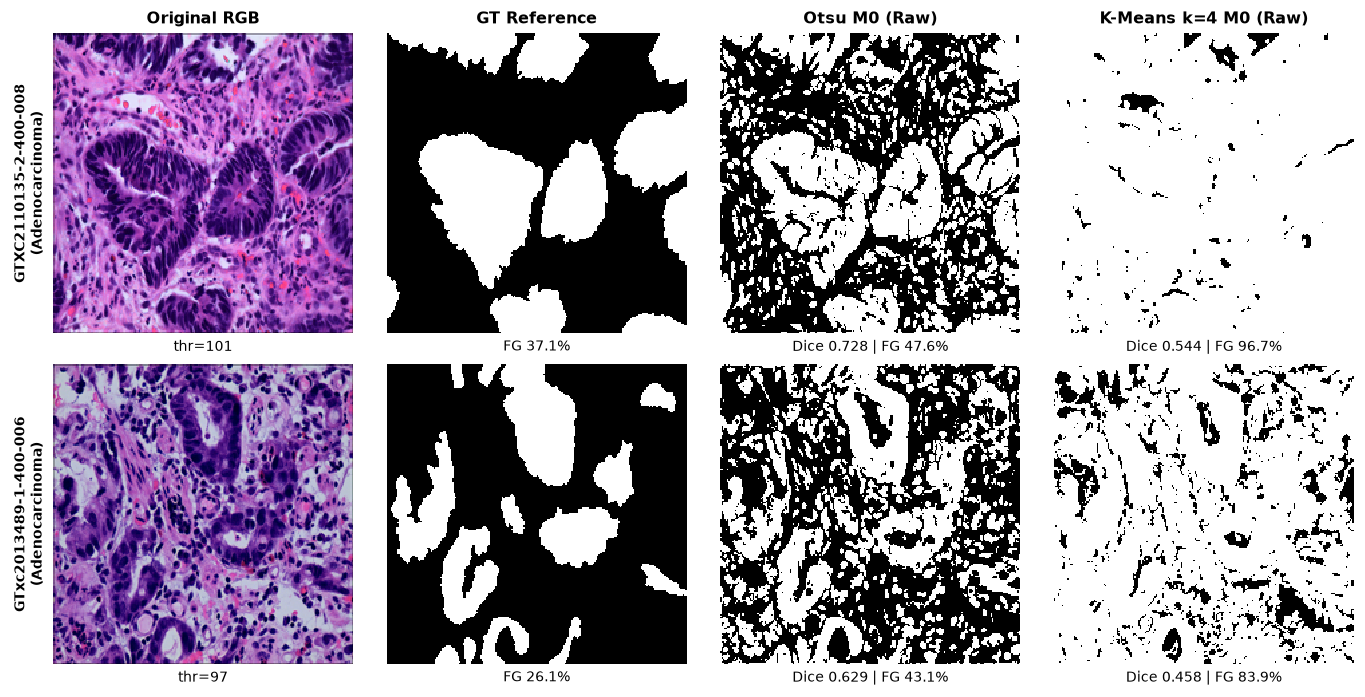

In [3]:
fig_seed = plot_seed_baseline_grid(PROJECT_ROOT, SEED_CASE_IDS)
finish_figure(fig_seed, show=True, close=True)

## 3. Penerapan Pascaproses (`M0`, `M1`, `M2`) & Perbandingan Before/After

Pada setiap panel: komponen `<16 px` ditandai *coral-red* untuk menekankan partikel yang dihapus `M1` dan fragmen kecil yang kembali terbentuk pada `M2`, sedangkan peta transisi `M0→M2` memisahkan piksel tetap, dihapus `M1`, dihapus `OPEN`, dan ditambah `CLOSE`.

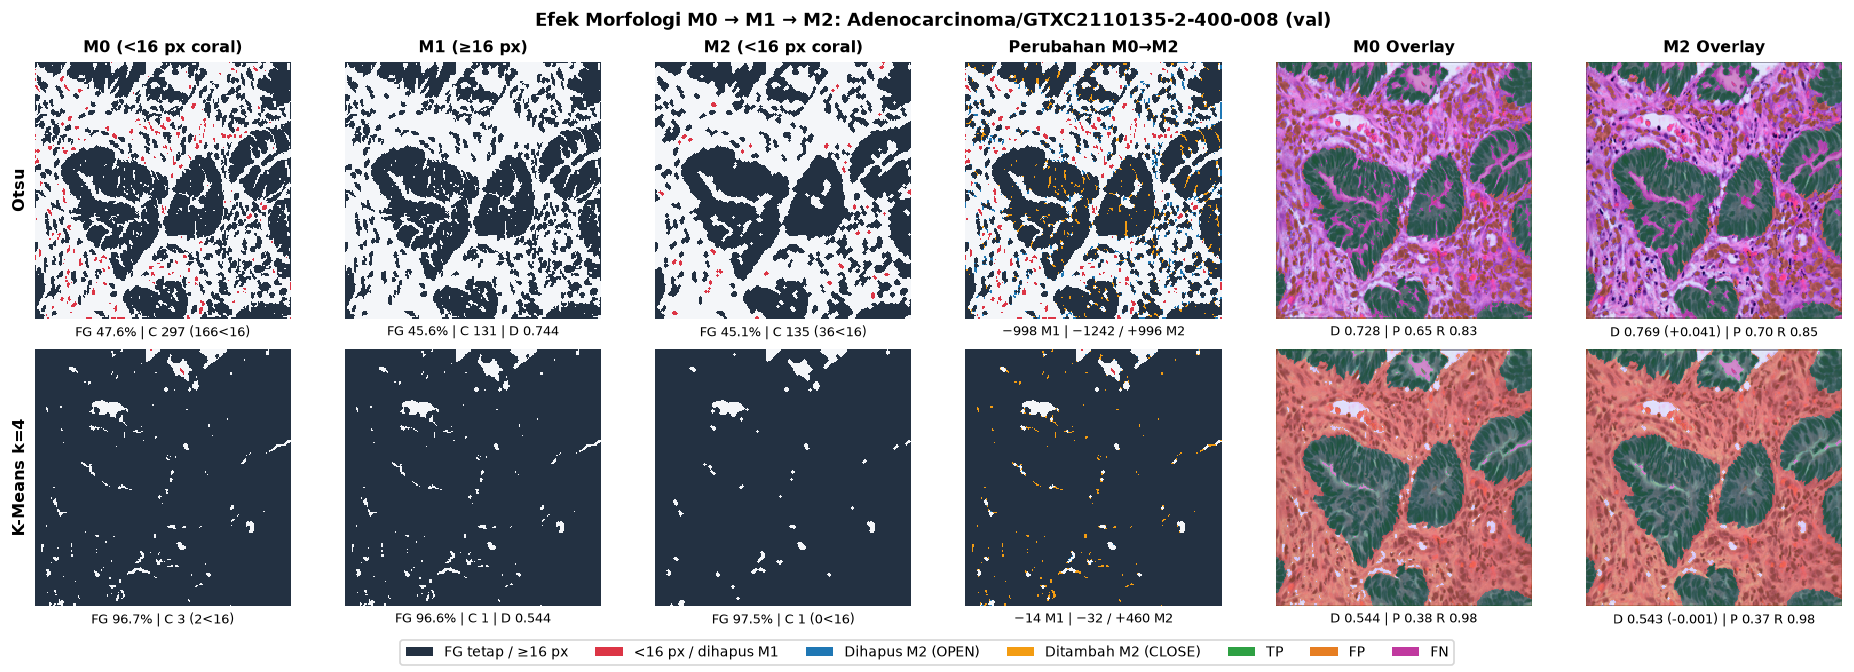

In [4]:
fig_case_0 = plot_case_morphology_progression(PROJECT_ROOT, SEED_CASE_IDS[0])
finish_figure(fig_case_0, show=True, close=True)

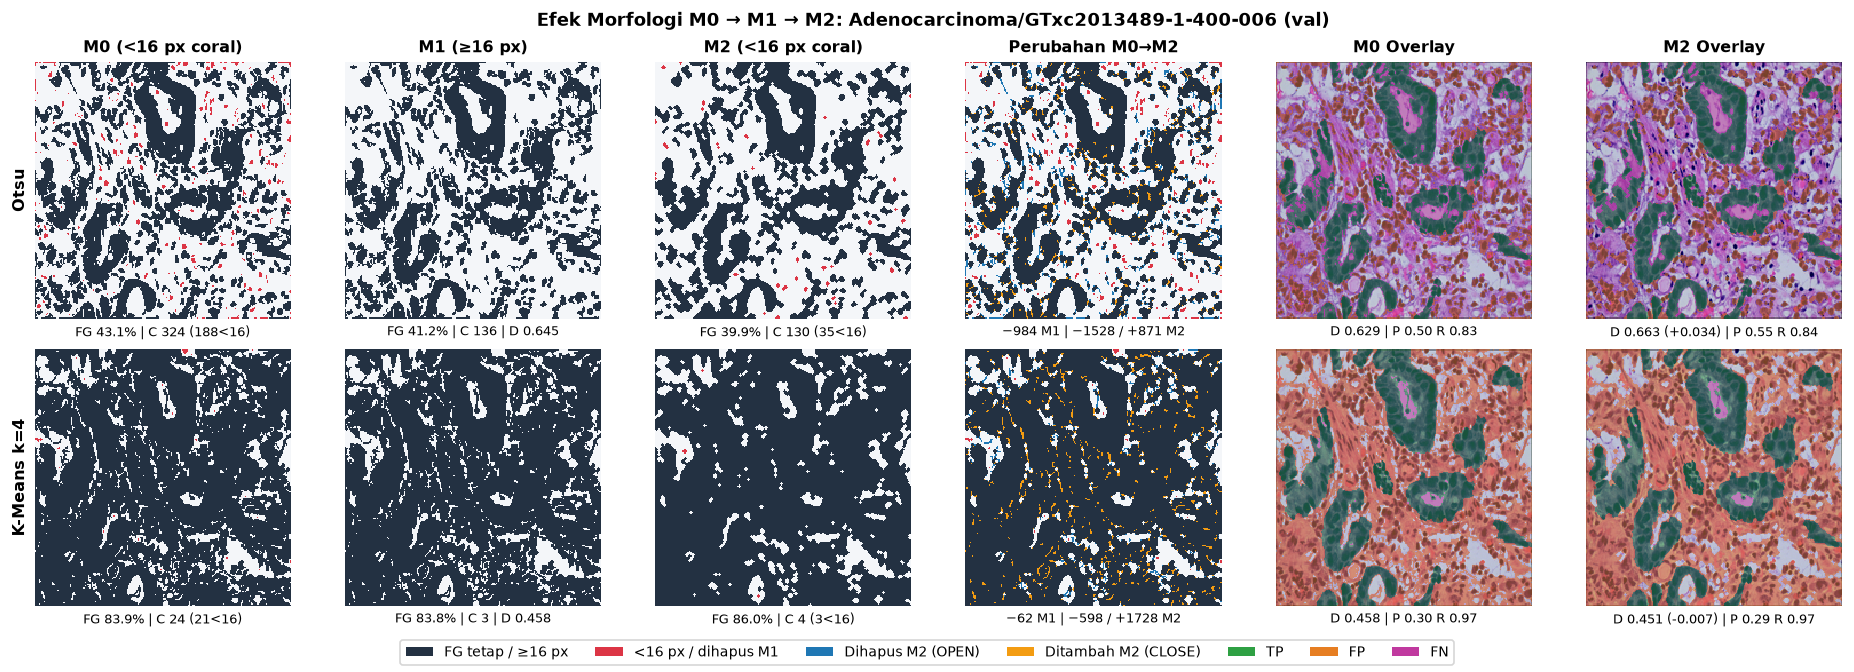

In [5]:
fig_case_1 = plot_case_morphology_progression(PROJECT_ROOT, SEED_CASE_IDS[1])
finish_figure(fig_case_1, show=True, close=True)

In [6]:
summary_rows = []
for sid in SEED_CASE_IDS:
    _, _, ref, _, states = _load_case_bundle(PROJECT_ROOT, sid)
    for fam in ("otsu", "k4"):
        st = states[fam]
        _, px = render_transition_diff_rgb(st["M0"], st["M1"], st["M2"])
        for stage in ("M0", "M1", "M2"):
            mask = st[stage]
            met = binary_segmentation_metrics(mask, ref)
            areas = connected_component_areas(mask)
            summary_rows.append(
                {
                    "sample_id": sid.split("/", 1)[1],
                    "family": fam,
                    "stage": stage,
                    "dice": round(float(met["dice"]), 4),
                    "iou": round(float(met["iou"]), 4),
                    "precision": round(float(met["precision"]), 4),
                    "recall": round(float(met["recall"]), 4),
                    "fg_pct": round(100.0 * float(met["predicted_foreground_fraction"]), 2),
                    "comp": int(len(areas)),
                    "small_lt16": int((areas < 16).sum()),
                    "rem_M1_px": px["removed_m1_px"] if stage == "M1" else 0,
                    "open_rem_px": px["removed_m2_px"] if stage == "M2" else 0,
                    "close_add_px": px["added_m2_px"] if stage == "M2" else 0,
                }
            )
display(pd.DataFrame(summary_rows))

,sample_id,family,stage,dice,iou,precision,recall,fg_pct,comp,small_lt16,rem_M1_px,open_rem_px,close_add_px
0,GTXC2110135-2-400-008,otsu,M0,0.7275,0.5718,0.6472,0.8307,47.61,297,166,0,0,0
1,GTXC2110135-2-400-008,otsu,M1,0.7444,0.5929,0.6748,0.8300,45.62,131,0,998,0,0
2,GTXC2110135-2-400-008,otsu,M2,0.7687,0.6243,0.7002,0.8521,45.13,135,36,0,1242,996
3,GTXC2110135-2-400-008,k4,M0,0.5440,0.3736,0.3764,0.9809,96.66,3,2,0,0,0
4,GTXC2110135-2-400-008,k4,M1,0.5437,0.3734,0.3762,0.9802,96.64,1,0,14,0,0
5,GTXC2110135-2-400-008,k4,M2,0.5426,0.3723,0.3745,0.9845,97.49,1,0,0,32,460
6,GTxc2013489-1-400-006,otsu,M0,0.6289,0.4587,0.5048,0.8339,43.13,324,188,0,0,0
7,GTxc2013489-1-400-006,otsu,M1,0.6452,0.4762,0.5272,0.8313,41.17,136,0,984,0,0
8,GTxc2013489-1-400-006,otsu,M2,0.6631,0.4960,0.5487,0.8378,39.86,130,35,0,1528,871
9,GTxc2013489-1-400-006,k4,M0,0.4580,0.2970,0.3002,0.9652,83.92,24,21,0,0,0


**Temuan kedua kasus awal:**
- Pada kedua citra, `Otsu` membaik bertahap (`GTXC2110135`: *Dice* `0.7275 → 0.7444 → 0.7687`; `GTxc2013489`: `0.6289 → 0.6452 → 0.6631`) karena `M1` membersihkan ratusan *speckle* *false positive* latar belakang dan `M2` menutup celah kecil di dalam kelenjar padat, namun menyisakan kembali `36` dan `35` fragmen `<16 px`.
- Sebaliknya, `K-Means k=4` sudah *over-segmented* ekstrem (`FG 96.7%` dan `83.9%` vs GT `37.1%` dan `26.1%`), sehingga `M1` hampir tak berdampak (`14–62 px` saja) dan `M2 CLOSE` justru memperluas *FP* (`+460` dan `+1.728 px`), sedikit menurunkan *Dice*.

## 4. Diagnostik Tingkat Dataset & Kasus Representatif Deterministik

Evaluasi penuh pada kohort `val` (`n = 372`) diverifikasi bernilai identik (`atol = 1e-10`) terhadap CSV validasi tersimpan serta `morphology_diagnostics_2x3.csv`. Pemilihan kasus representatif diurutkan deterministik berdasarkan `ΔDice` dan *tie-breaker* `sample_id`.

In [7]:
val_df, area_pools = evaluate_val_morphology_cohort(
    PROJECT_ROOT,
    split="val",
    verify_against_saved=True,
)
rep_cases = select_deterministic_representative_cases(val_df)
display(rep_cases.round(4))

,role,family,sample_id,category,dice_M0,dice_M1,dice_M2,delta_M1_M0,delta_M2_M1,delta_M2_M0
0,Otsu: Max Gain (M2−M0),otsu,Adenocarcinoma/GTXC2015362-9-400-008,Adenocarcinoma,0.6359,0.6530,0.6883,0.0172,0.0353,0.0525
1,Otsu: Max Polyp Regress (M2−M1),otsu,Polyp/GT2016854-1-400-004,Polyp,0.5332,0.5380,0.4958,0.0048,-0.0422,-0.0373
2,Otsu: Max Regress (M2−M0),otsu,Adenocarcinoma/GT2014744-1-400-002,Adenocarcinoma,0.5437,0.5133,0.4715,-0.0304,-0.0418,-0.0722
3,K-Means k=4: Max Gain (M2−M0),k4,Adenocarcinoma/GT2014744-1-400-002,Adenocarcinoma,0.9299,0.9296,0.9617,-0.0003,0.0321,0.0318
4,K-Means k=4: Max Regress (M2−M0),k4,Polyp/GT1815553-1-400-001,Polyp,0.5812,0.5774,0.5492,-0.0038,-0.0282,-0.0320
5,Otsu: Negligible |ΔDice| (M2−M0),otsu,Low-grade IN/GTXC2015362-3-400-003,Low-grade IN,0.6957,0.6934,0.6957,-0.0023,0.0023,-0.0000
6,K-Means k=4: Negligible |ΔDice| (M1−M0),k4,Low-grade IN/GTXC2015362-5-400-002,Low-grade IN,0.6687,0.6687,0.6536,0.0000,-0.0151,-0.0151


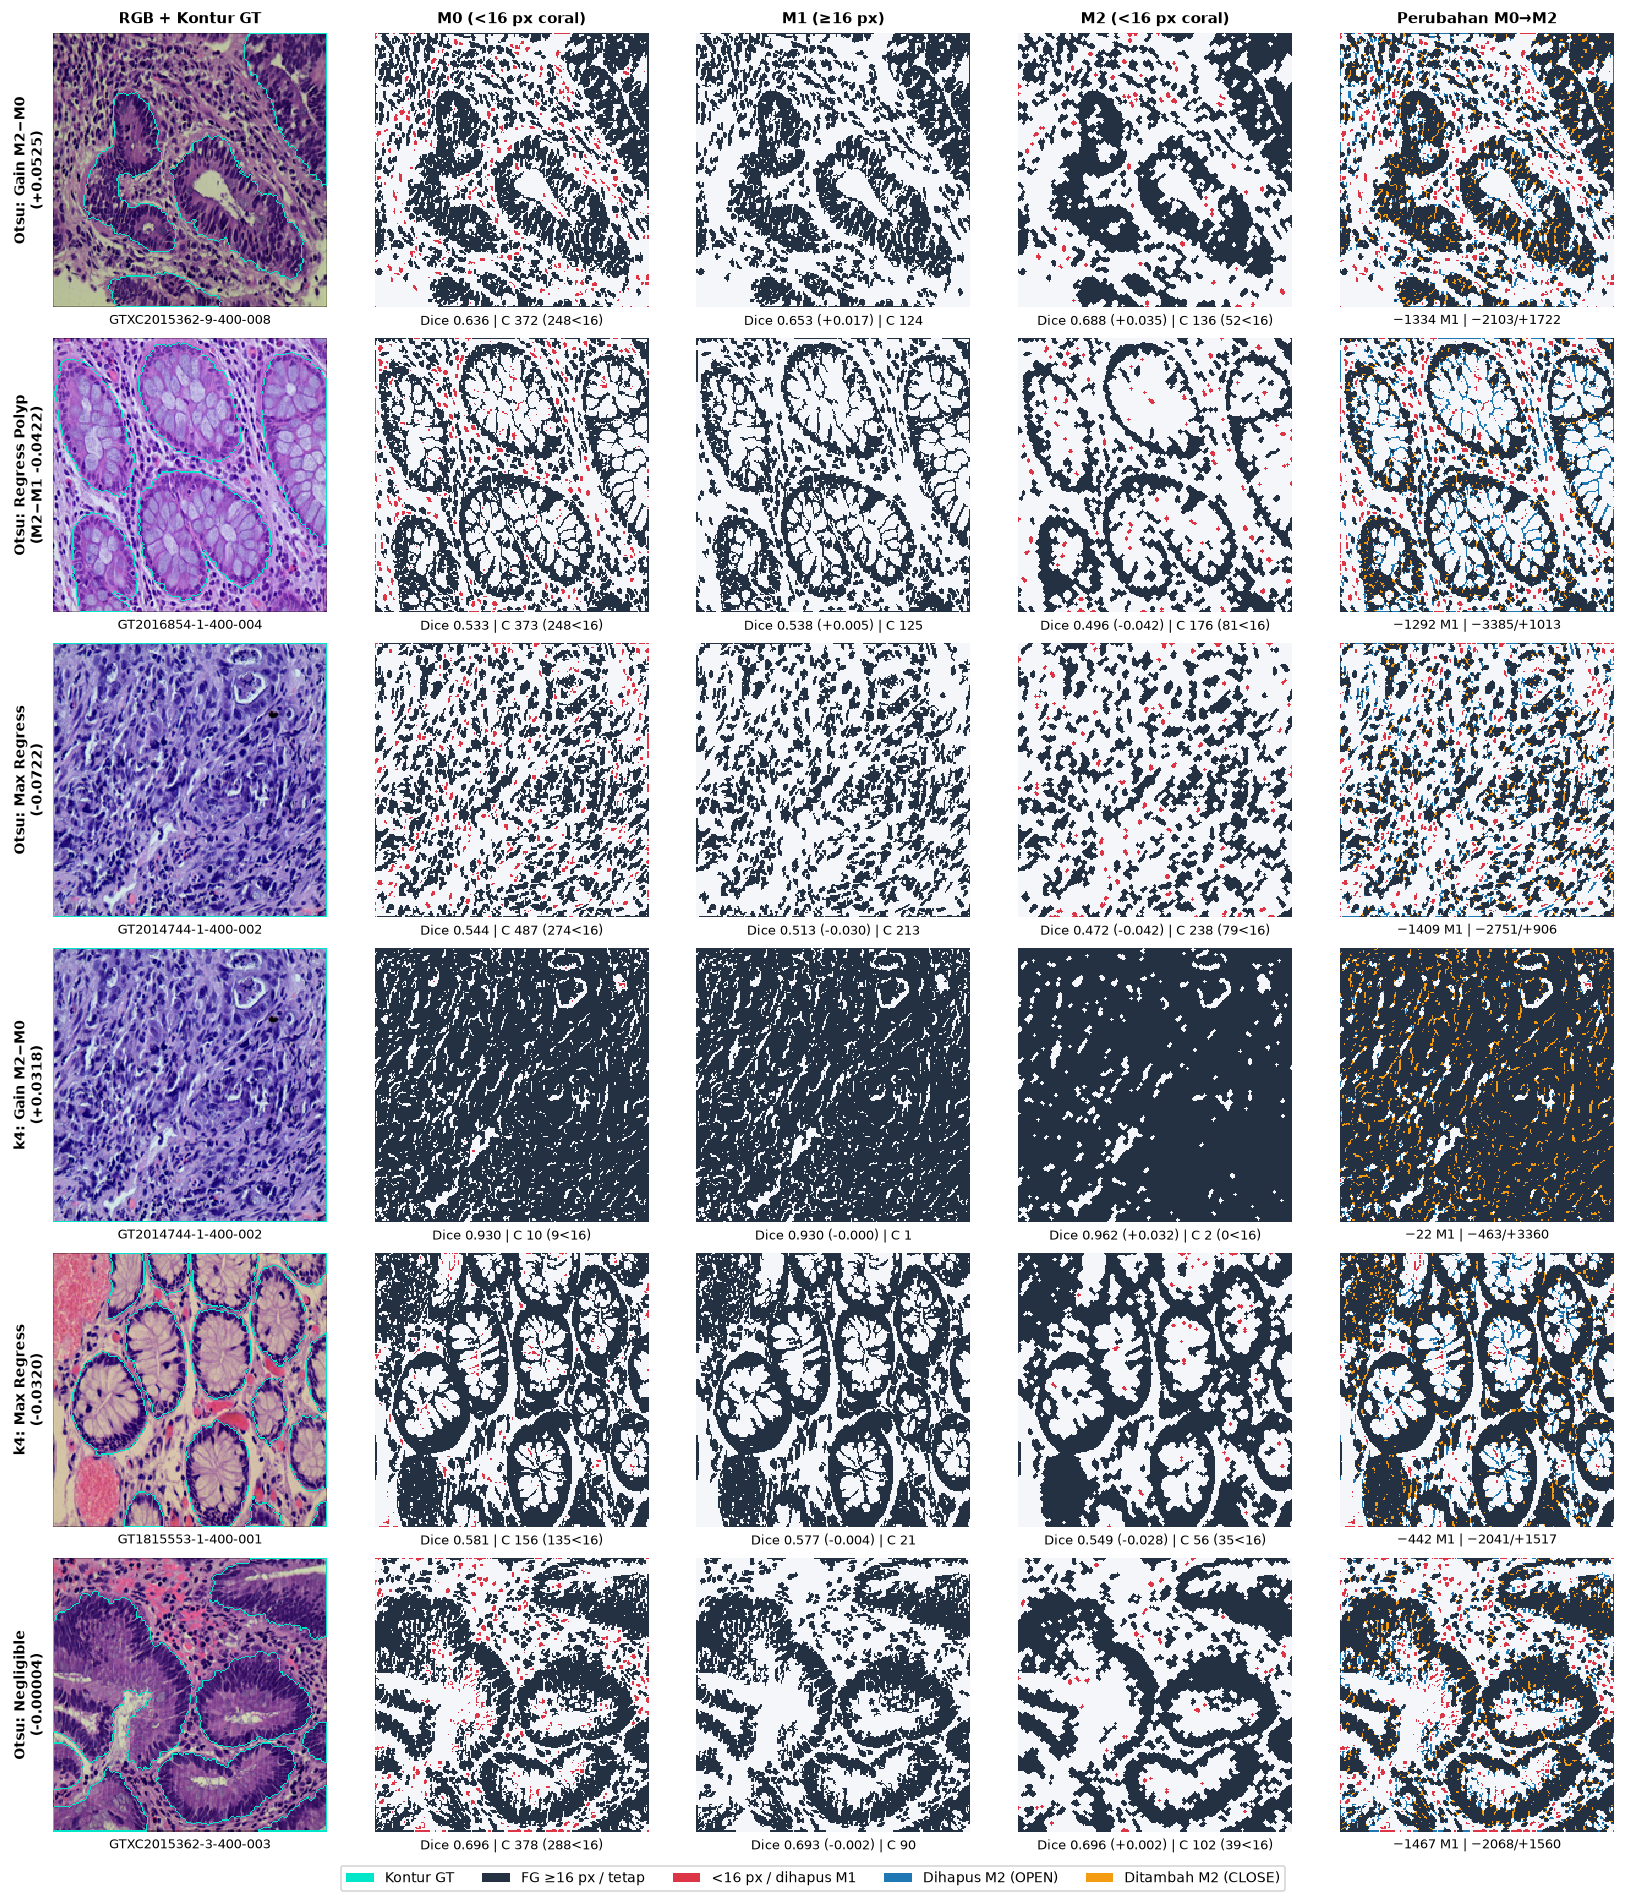

In [8]:
case_specs = [
    (f"Otsu: Gain M2−M0\n({rep_cases.loc[0, 'delta_M2_M0']:+.4f})", "otsu", rep_cases.loc[0, "sample_id"]),
    (f"Otsu: Regress Polyp\n(M2−M1 {rep_cases.loc[1, 'delta_M2_M1']:+.4f})", "otsu", rep_cases.loc[1, "sample_id"]),
    (f"Otsu: Max Regress\n({rep_cases.loc[2, 'delta_M2_M0']:+.4f})", "otsu", rep_cases.loc[2, "sample_id"]),
    (f"k4: Gain M2−M0\n({rep_cases.loc[3, 'delta_M2_M0']:+.4f})", "k4", rep_cases.loc[3, "sample_id"]),
    (f"k4: Max Regress\n({rep_cases.loc[4, 'delta_M2_M0']:+.4f})", "k4", rep_cases.loc[4, "sample_id"]),
    (f"Otsu: Negligible\n({rep_cases.loc[5, 'delta_M2_M0']:+.5f})", "otsu", rep_cases.loc[5, "sample_id"]),
]
fig_rep = plot_representative_cases_grid(PROJECT_ROOT, case_specs)
finish_figure(fig_rep, show=True, close=True)

**Pola mekanistik dari kasus deterministik:**
- `Adenocarcinoma/GT2014744-1-400-002` (GT memenuhi hampir seluruh *patch*, `Prec = 1.0`) memperlihatkan paradoks operator yang sama: pada `Otsu` yang terfragmentasi tipis (`FG 37.3%`), `M1` dan `OPEN` membuang jaringan asli (`Dice 0.544 → 0.472`), sedangkan pada `k4` (`FG 86.9%`), `CLOSE` menutup rongga internal sehingga melonjak (`0.930 → 0.962`).
- Pada kasus regresi *Polyp* (`GT2016854` pada `Otsu`, `GT1815553` pada `k4`), `OPEN` mengikis struktur epitel tipis dan memecah komponen sehingga *Recall* turun tanpa kompensasi *CLOSE*.

## 5. Distribusi Komponen Terhubung (`M0`, `M1`, `M2`)

Perbandingan distribusi luas komponen dan rata-rata jumlah komponen antara `val` (`n = 372`) dan data pengembangan `train` tersimpan (`n = 1.535`).

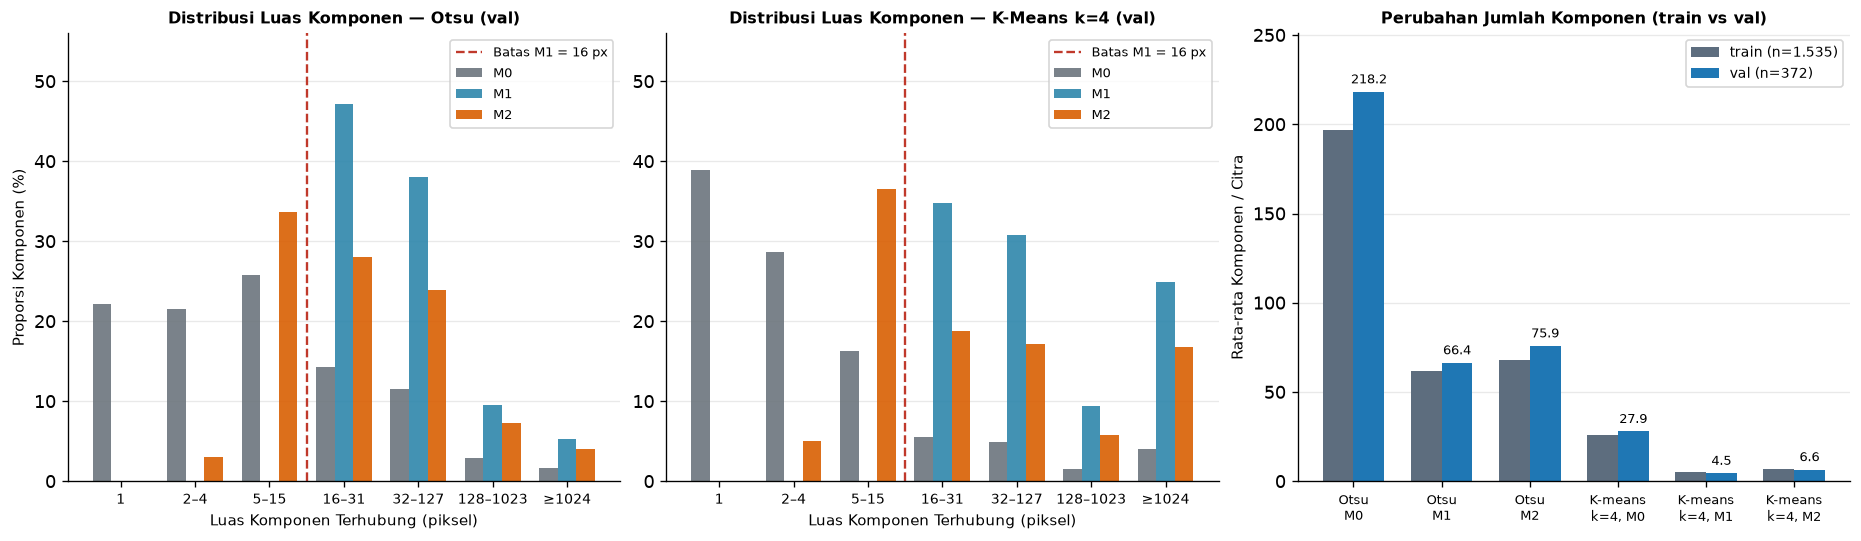

In [9]:
fig_comp = plot_component_distributions(area_pools, val_df, dev_diag)
finish_figure(fig_comp, show=True, close=True)

In [10]:
comp_rows = []
for fam in ("otsu", "k4"):
    for st in ("M0", "M1", "M2"):
        areas = area_pools[(fam, st)]
        sub_val = val_df.loc[val_df["family"].eq(fam)]
        train_cc = float(
            dev_diag.loc[
                dev_diag["split"].eq("train") & dev_diag["method"].eq(f"{fam}_{st}"),
                "component_count",
            ].mean()
        )
        comp_rows.append(
            {
                "method": f"{fam}_{st}",
                "val_total_comp": int(len(areas)),
                "val_lt16_count": int((areas < 16).sum()),
                "val_lt16_pct": round(100.0 * float((areas < 16).mean()), 1),
                "val_mean_comp": round(float(sub_val[f"cc_{st}"].mean()), 2),
                "train_mean_comp": round(train_cc, 2),
                "val_fg_pct": round(float(sub_val[f"fg_pct_{st}"].mean()), 2),
            }
        )
display(pd.DataFrame(comp_rows))

,method,val_total_comp,val_lt16_count,val_lt16_pct,val_mean_comp,train_mean_comp,val_fg_pct
0,otsu_M0,81187,56480,69.6,218.24,196.91,53.05
1,otsu_M1,24707,0,0.0,66.42,61.54,51.65
2,otsu_M2,28222,10365,36.7,75.87,67.99,51.09
3,k4_M0,10393,8728,84.0,27.94,26.03,85.08
4,k4_M1,1665,0,0.0,4.48,5.40,84.94
5,k4_M2,2442,1013,41.5,6.56,6.81,86.86


## 6. Cakupan Foreground, Perubahan Piksel (`TP`/`FP`), dan Metrik Kategori

Analisis terpadu mencakup seluruh metrik (`FG%`, piksel terhapus/tertambah terpecah atas `TP` vs `FP`, `Dice`, `IoU`, `Precision`, dan `Recall`) pada kohort `val`.

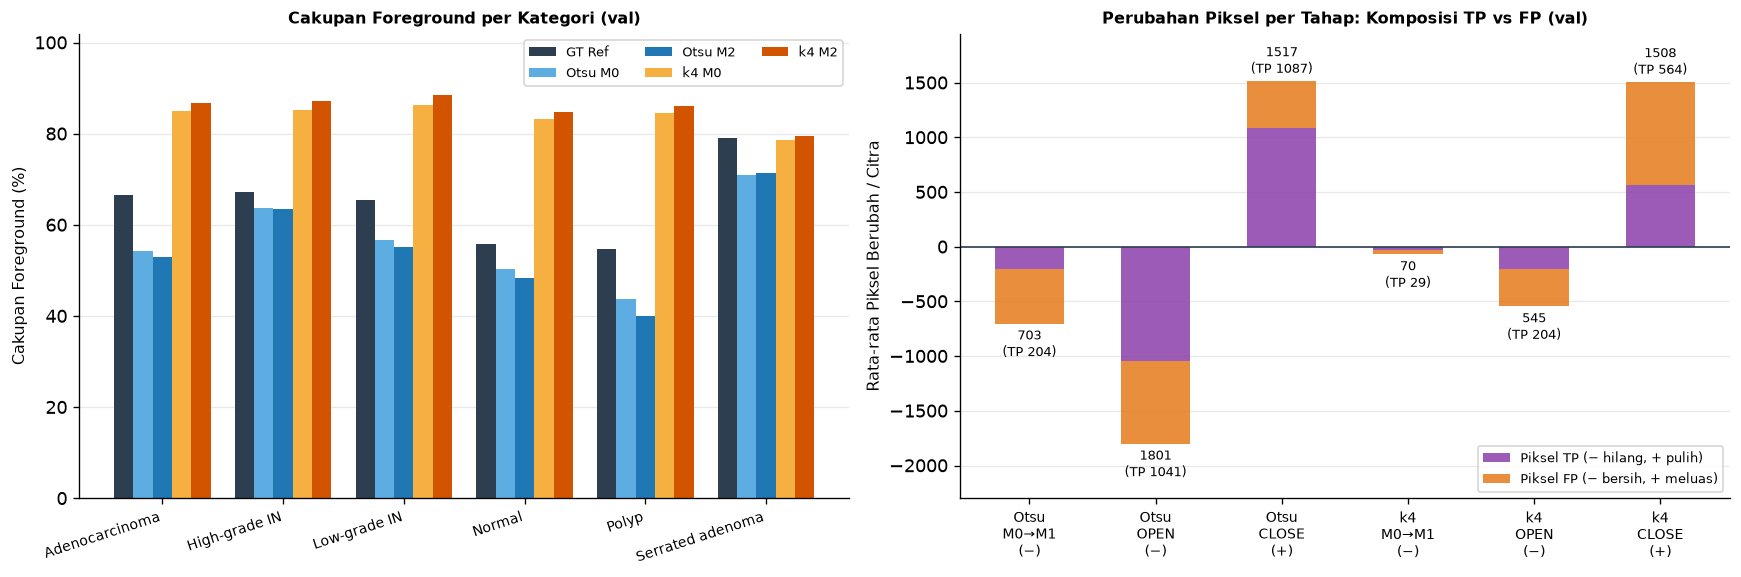

In [11]:
fig_cov = plot_coverage_and_pixel_flips(val_df)
finish_figure(fig_cov, show=True, close=True)

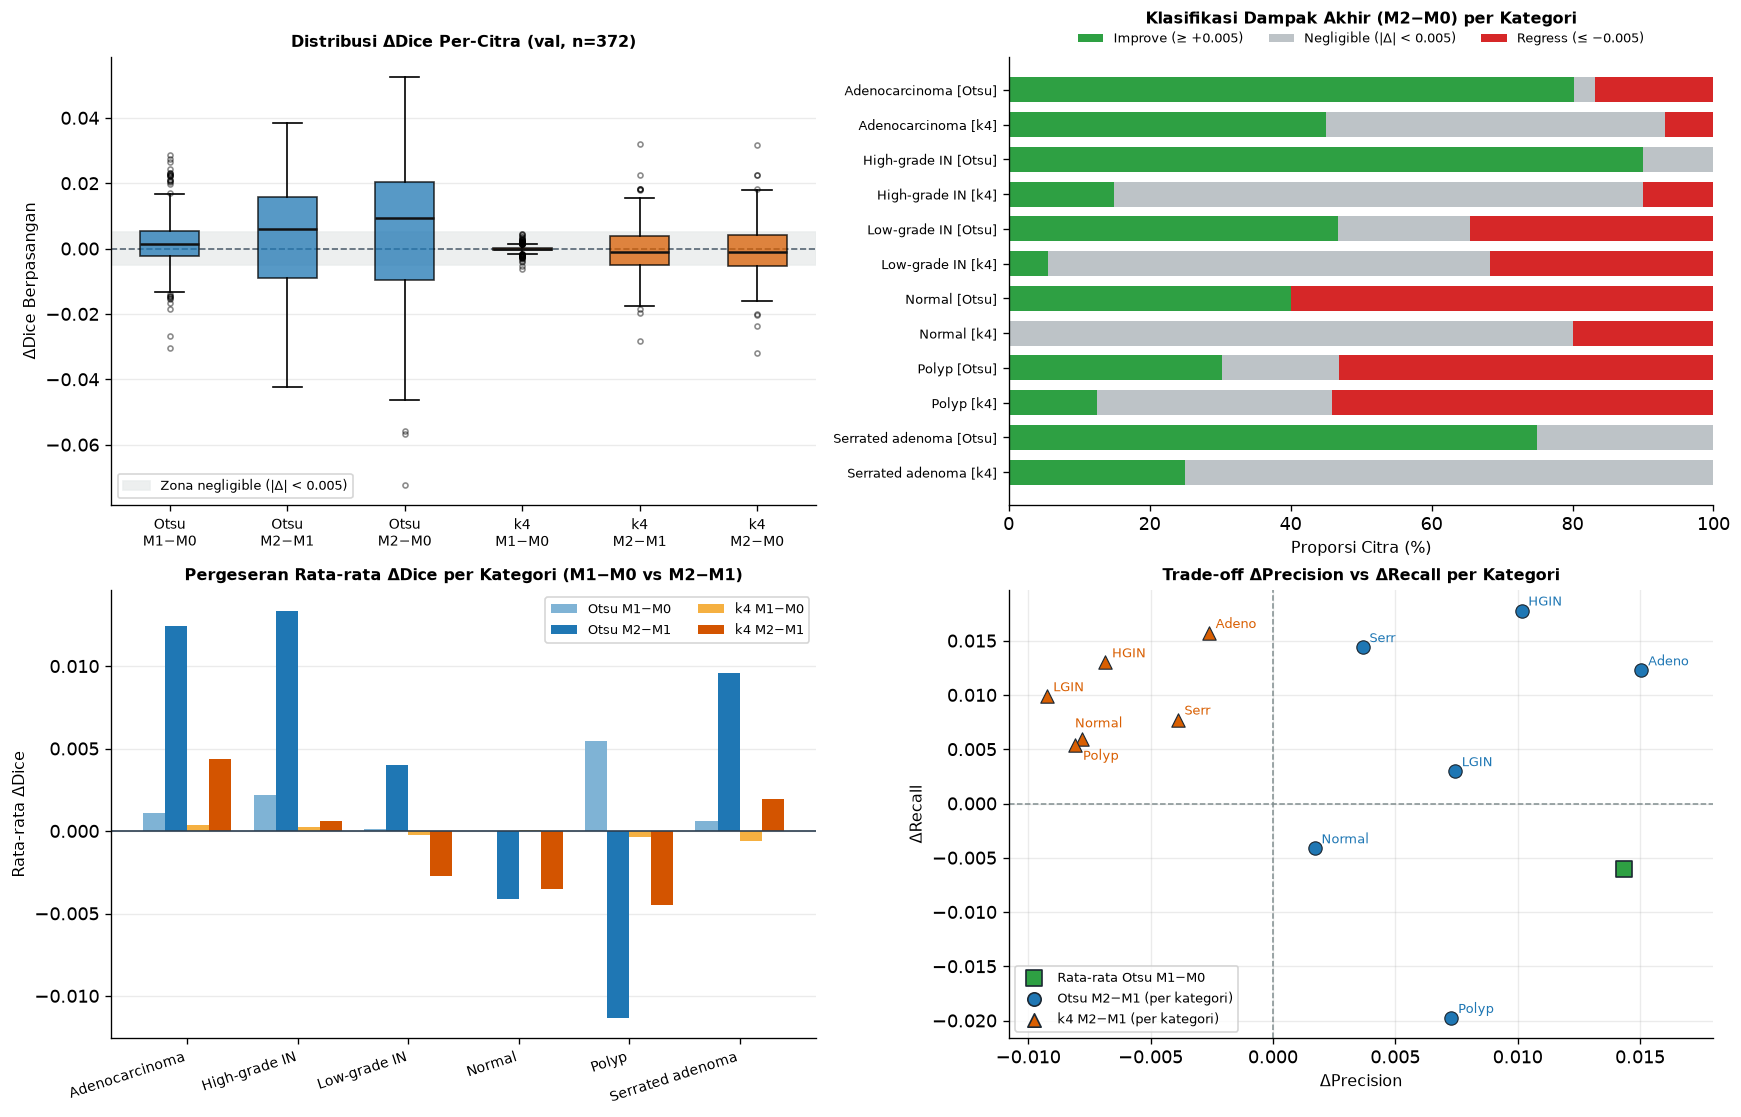

In [12]:
fig_met = plot_metric_distributions_and_tradeoffs(val_df)
finish_figure(fig_met, show=True, close=True)

In [13]:
cat_summary = summarize_transitions_by_category(val_df)
display(cat_summary.round(4))

,family,category,n,dice_M0,dice_M1,dice_M2,d_dice_M1_M0,d_dice_M2_M1,d_dice_M2_M0,d_iou_M2_M0,...,d_rec_M2_M1,fg_pct_M0,fg_pct_M1,fg_pct_M2,cc_M0,cc_M1,cc_M2,improve_n,negligible_n,regress_n
0,otsu,Adenocarcinoma,131,0.7428,0.7439,0.7563,0.0011,0.0124,0.0135,0.0194,...,0.0123,54.3403,53.0581,52.9871,220.7405,66.9160,74.3359,105,4,22
1,otsu,High-grade IN,20,0.8091,0.8113,0.8246,0.0022,0.0134,0.0156,0.0223,...,0.0178,63.6770,62.7184,63.4336,149.1000,40.6500,47.1000,18,2,0
2,otsu,Low-grade IN,107,0.7069,0.7071,0.7111,0.0002,0.0040,0.0042,0.0067,...,0.0030,56.6947,55.4160,55.0776,198.1215,58.2523,67.5888,50,20,37
3,otsu,Normal,10,0.6535,0.6535,0.6494,0.0000,-0.0041,-0.0041,-0.0004,...,-0.0041,50.3946,49.1803,48.4313,205.2000,73.7000,70.2000,4,0,6
4,otsu,Polyp,96,0.6107,0.6162,0.6048,0.0055,-0.0113,-0.0059,-0.0037,...,-0.0197,43.8077,41.9241,40.0480,264.0729,83.0625,97.8229,29,16,51
5,otsu,Serrated adenoma,8,0.8164,0.8170,0.8266,0.0006,0.0096,0.0102,0.0141,...,0.0144,70.9906,70.4782,71.4772,85.7500,23.0000,27.1250,6,2,0
6,otsu,Macro (6 cat),372,0.7232,0.7248,0.7288,0.0016,0.0040,0.0056,0.0098,...,0.0039,56.6508,55.4625,55.2425,187.1641,57.5968,64.0288,212,44,116
7,k4,Adenocarcinoma,131,0.8033,0.8037,0.8081,0.0004,0.0044,0.0047,0.0082,...,0.0157,84.9308,84.8134,86.6813,22.9008,4.5038,6.2214,59,63,9
8,k4,High-grade IN,20,0.8333,0.8336,0.8343,0.0003,0.0006,0.0009,0.0016,...,0.0130,85.2972,85.1771,87.2005,20.9000,4.3000,5.1500,3,15,2
9,k4,Low-grade IN,107,0.7733,0.7731,0.7703,-0.0002,-0.0027,-0.0030,-0.0037,...,0.0099,86.4110,86.2783,88.4797,25.1682,4.5794,5.0935,6,67,34


In [14]:
hashes_after = file_sha256_map(PROJECT_ROOT, tracked_inputs)
assert hashes_after == input_hashes_before, "Input file mutation detected!"
print("Integrity OK: seluruh berkas masukan, split beku, model, dan CSV historis tetap identik.")

Integrity OK: seluruh berkas masukan, split beku, model, dan CSV historis tetap identik.


## 7. Ringkasan Diagnostik & Rekomendasi Task 2

### Manfaat Teramati
- **Pembersihan *speckle* (`M1`) pada `Otsu`:** Menghapus `56.480` komponen `<16 px` (`69.6%` total komponen `M0`) dengan rasio `FP:TP ≈ 2.45:1` (`499.0 FP` vs `203.7 TP px/citra`), meningkatkan *Precision* di seluruh 6 kategori (`+0.0040` s/d `+0.0250`) dan menaikkan *Dice* pada `238/372` citra `val` (makro `+0.0016`).
- **Penutupan rongga (`M2`) pada tipe lesi padat (`Otsu`):** Pada *Adenocarcinoma*, *High-grade IN*, dan *Serrated adenoma* (`val`), tahap `CLOSE` memulihkan `955–1.457 TP px/citra` dibanding `268–453 FP px/citra`, sehingga `M2` meningkatkan *Precision* dan *Recall* sekaligus (`ΔDice M2−M1 = +0.0124`, `+0.0134`, `+0.0096`).

### Regresi & Keterbatasan Utama
- **Erosi struktur tipis pada `Polyp` & `Normal` (`Otsu M2`):** Operasi `OPEN 3×3 cross` membuang lebih banyak *TP* daripada *FP* (`1.103 TP` vs `833 FP px/citra` pada *Polyp* `val`) dan celah antar-struktur tipis gagal dipulihkan oleh `CLOSE` (`+553 TP`), menyebabkan *Recall* turun `−0.0197` dan *Dice* regresi `−0.0113`. Pola penyusutan cakupan dan jumlah komponen tetap konsisten antara `train` (`n = 1.535`) dan `val` (`n = 372`).
- **`M1` netral & `M2` kontra-produktif pada `K-Means k=4`:** Karena `k4_M0` sudah *over-segmented* (`FG ~85%`, *Recall* `~0.91`, *Precision* `~0.70`), `M1` hanya membuang `69.8 px/citra` (`370/372` citra `|ΔDice| < 0.005`), sementara `M2 CLOSE` menambahkan `1.67×` lebih banyak *FP* dibanding *TP* (`+943.6 FP` vs `+564.4 TP px/citra`), menurunkan *Precision* di semua kategori dan memperburuk `210/372` citra dibanding `M1`.
- **Urutan operasi `M1 → M2` memicu fragmentasi ulang:** Karena penghapusan `<16 px` dijalankan *sebelum* `OPEN → CLOSE`, pemutusan jembatan tipis oleh `OPEN` menciptakan kembali `10.365` komponen `<16 px` pada `otsu_M2` (`36.7%` total komponen) dan `1.013` komponen `<16 px` pada `k4_M2` (`41.5%`).

### Rekomendasi Investigasi Task 2
1. **Perbaikan urutan *connected-component pruning*:** Uji pemindahan/penambahan filter ukuran komponen *setelah* operasi morfologi agar fragmen `<16 px` sisa `OPEN` tidak tertinggal pada masker final.
2. **Pemisahan `OPEN` vs *hole-filling* / `CLOSE`:** Uji pengisian rongga internal selektif tanpa `OPEN` agresif pada masker terfragmentasi (`Otsu`), guna mempertahankan gain *Adenocarcinoma/HGIN* tanpa merusak *Polyp/Normal*.
3. **Pascaproses adaptif per keluarga segmentasi:** Hindari `CLOSE` penambah batas luar pada `K-Means k=4` yang sudah ber-cakupan tinggi (`~85% FG`), dan evaluasi seluruh kandidat pascaproses secara eksklusif pada split `train` / CV berbasis `group_id`.